# 01 · Data sources and collection
**Indian Farmer Revenue, Crop Profitability & Market Intelligence System**

This notebook inventories every raw input, records where it comes from, and checks the provenance of the production data.

| Domain | Dataset | Publisher |
|---|---|---|
| Production | District-wise, season-wise crop production (APY), 1997-98 to 2019-20 | DES, Ministry of Agriculture & FW |
| MSP | Minimum Support Prices / FRP | CACP, DA&FW (PIB releases, DES, data.gov.in) |
| Cost | Cost of cultivation, 2008-09 to 2013-14 | DES Cost of Cultivation Scheme |
| Mandi prices | Maharashtra APMC monthly 2014-16; AGMARKNET daily 30-Sep-2024 and 21-Jul to 24-Sep-2026 | GoM APMC; DMI / AGMARKNET |
| Inflation | Consumer price index, India (2010 = 100) | World Bank WDI (IMF IFS) |
| Weather | Sub-divisional monthly rainfall 1901-2015 | IMD |

Government portals blocked automated download, so raw files are copies of the data.gov.in releases (mirrored on GitHub). Section 3 verifies the production mirror against the original data.gov.in release.

| | |
|---|---|
| **Objective** | Inventory every raw input and confirm where it comes from. |
| **Dataset** | All raw files in data/raw/ (DES APY, MSP, AGMARKNET, DES cost of cultivation, IMD rainfall, World Bank CPI). |
| **Business question** | Can each number in the project be traced to an official source? |
| **Method** | List files, sizes and coverage; compare two vintages of the APY production data. |
| **Output** | Source inventory; vintage comparison chart. |
| **Key finding** | The two APY vintages agree on only ~83% of state-year-crop totals; the later vintage is used because the older one has gaps in its final years. |

In [1]:
import sys, sqlite3, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.config import RAW, CURATED, PROC, RESULTS, FIGURES, DB_PATH, connect_ro
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
BLUE, ORANGE, AQUA, YELLOW, PINK, RED, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#e34948", "#9aa19c"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold", "axes.titlesize": 11})
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight"); plt.show()

## 1. Raw file inventory

In [2]:
inv = []
for f in sorted(list(RAW.glob("*.csv")) + list(RAW.glob("*.csv.gz"))):
    df = pd.read_csv(f, low_memory=False)
    inv.append({"file": f.name, "rows": len(df), "columns": df.shape[1], "size_MB": round(f.stat().st_size / 1e6, 2),
                "first_columns": ", ".join(map(str, df.columns[:5]))})
pd.DataFrame(inv)

,file,rows,columns,size_MB,first_columns
0,agmarknet_daily_2026.csv.gz,463023,11,4.83,"state, district, market, commodity, variety"
1,apy_district_1997_2019.csv,326846,9,20.28,"Unnamed: 0, state, district, crop, year"
2,cmo_msp_mandi.csv,155,5,0.01,"commodity, year, Type, msprice, msp_filter"
3,cpi_india_worldbank.csv,26,4,0.00,"year, cpi_2010_100, source, source_url"
4,crop_production.csv,246091,7,15.32,"State_Name, District_Name, Crop_Year, Season, ..."
5,crops_price_msp.csv,29,11,0.00,"Commodities(rs/quin), 2002, 2004, 2005, 2006"
6,culti_cost.csv,50,20,0.01,"Crop, State/ UT Name, Cost of Cultivation (`/H..."
7,mandi_dataset_2024.csv,15224,10,1.44,"State, District, Market, Commodity, Variety"
8,mandi_monthly_cmo.csv,62429,11,4.95,"APMC, Commodity, Year, Month, arrivals_in_qtl"
9,rainfall_in_india.csv,4116,19,0.44,"DIVISION, YEAR, JAN, FEB, MAR"


## 2. A first look at each source

In [3]:
for f in ["apy_district_1997_2019.csv", "mandi_monthly_cmo.csv", "mandi_dataset_2024.csv", "culti_cost.csv", "rainfall_in_india.csv"]:
    print("=" * 100, "\n", f)
    display(pd.read_csv(RAW / f, nrows=3))

 apy_district_1997_2019.csv


,Unnamed: 0,state,district,crop,year,season,area,production,yield
0,0,Andaman and Nicobar Island,Nicobars,Arecanut,2007,Kharif,2439.6,3415,1.40
1,1,Andaman and Nicobar Island,Nicobars,Arecanut,2007,Rabi,1626.4,2277,1.40
2,2,Andaman and Nicobar Island,Nicobars,Arecanut,2008,Autumn,4147.0,3060,0.74


 mandi_monthly_cmo.csv


,APMC,Commodity,Year,Month,arrivals_in_qtl,min_price,max_price,modal_price,date,district_name,state_name
0,Ahmednagar,Bajri,2015,April,79,1406,1538,1463,2015-04,Ahmadnagar,Maharashtra
1,Ahmednagar,Bajri,2016,April,106,1788,1925,1875,2016-04,Ahmadnagar,Maharashtra
2,Ahmednagar,Wheat(Husked),2015,April,1253,1572,1890,1731,2015-04,Ahmadnagar,Maharashtra


 mandi_dataset_2024.csv


,State,District,Market,Commodity,Variety,Grade,Arrival_Date,Min_x0020_Price,Max_x0020_Price,Modal_x0020_Price
0,Andaman and Nicobar,North and Middle Andaman,Mayabandar,Bhindi(Ladies Finger),Bhindi,FAQ,30/09/2024,50,80,60
1,Andaman and Nicobar,North and Middle Andaman,Mayabandar,Coconut,Coconut,FAQ,30/09/2024,10,20,15
2,Andaman and Nicobar,North and Middle Andaman,Mayabandar,Leafy Vegetable,Leafy Vegetables,FAQ,30/09/2024,30,50,40


 culti_cost.csv


,Crop,State/ UT Name,Cost of Cultivation (`/Hectare) - A2+FL - 2008-09,Cost of Cultivation (`/Hectare) - A2+FL - 2009-10,Cost of Cultivation (`/Hectare) - A2+FL - 2010-11,Cost of Cultivation (`/Hectare) - A2+FL - 2011-12,Cost of Cultivation (`/Hectare) - A2+FL - 2012-13,Cost of Cultivation (`/Hectare) - A2+FL - 2013-14,Cost of Cultivation(`/Hectare) - C2 - 2008-09,Cost of Cultivation(`/Hectare) - C2 - 2009-10,Cost of Cultivation(`/Hectare) - C2 - 2010-11,Cost of Cultivation(`/Hectare) - C2 - 2011-12,Cost of Cultivation (`/Hectare) - C2 - 2012-13,Cost of Cultivation (`/Hectare) - C2 - 2013-14,Cost of Production (`/Quintal) - C2 - 2008-09,Cost of Production (`/Quintal) - C2 - 2009-10,Cost of Production (`/Quintal) - C2 - 2010-11,Cost of Production (`/Quintal) - C2 - 2011-12,Cost of Production (`/Quintal) - C2 - 2012-13,Cost of Production (`/Quintal) - C2 - 2013-14
0,Paddy,Andhra Pradesh,29664.84,35104.80,35090.78,37946.69,42669.85,46781.05,46450.20,54202.54,51505.34,58027.19,68149.69,72417.05,789.90,932.50,916.98,976.36,1135.01,1248.20
1,Paddy,Odisha,17478.05,19175.75,21894.98,27243.15,31723.25,35569.85,25909.05,28143.88,30318.40,35972.50,44091.78,46839.15,715.04,793.65,955.59,1221.44,1159.54,1408.40
2,Paddy,Punjab,25154.75,29031.73,30793.25,31248.72,37103.96,39686.81,45291.24,50650.21,51279.34,53813.93,64811.36,68382.86,669.86,773.18,836.46,904.30,945.73,1043.27


 rainfall_in_india.csv


,DIVISION,YEAR,JAN,FEB,MAR,APR,MAY,JUN,JUL,AUG,SEP,OCT,NOV,DEC,ANNUAL,Jan-Feb,Mar-May,Jun-Sep,Oct-Dec
0,ANDAMAN & NICOBAR ISLANDS,1901,49.2,87.1,29.2,2.3,528.8,517.5,365.1,481.1,332.6,388.5,558.2,33.6,3373.2,136.3,560.3,1696.3,980.3
1,ANDAMAN & NICOBAR ISLANDS,1902,0.0,159.8,12.2,0.0,446.1,537.1,228.9,753.7,666.2,197.2,359.0,160.5,3520.7,159.8,458.3,2185.9,716.7
2,ANDAMAN & NICOBAR ISLANDS,1903,12.7,144.0,0.0,1.0,235.1,479.9,728.4,326.7,339.0,181.2,284.4,225.0,2957.4,156.7,236.1,1874.0,690.6


## 3. Provenance check: how does the 1997-2019 production file compare with the data.gov.in release?
`crop_production.csv` is the older data.gov.in release (1997-2015). `apy_district_1997_2019.csv` is a longer export of the same DES APY series. Before choosing one, compare them on overlapping years.

In [4]:
old = pd.read_csv(RAW / "crop_production.csv")
new = pd.read_csv(RAW / "apy_district_1997_2019.csv")
old["Crop"] = old["Crop"].str.strip()
k_old = old.groupby(["State_Name", "Crop_Year", "Crop"])["Production"].sum()
new["crop_n"] = new["crop"].replace({"Cotton(Lint)": "Cotton(lint)", "Niger Seed": "Niger seed", "Dry Chillies": "Dry chillies"})
k_new = new.groupby(["state", "year", "crop_n"])["production"].sum()
cmp = pd.concat([k_old.rename("data_gov_in"), k_new.rename("mirror")], axis=1, join="inner")
cmp = cmp[cmp.index.get_level_values(1) <= 2014]
match = (np.isclose(cmp.data_gov_in, cmp.mirror, rtol=1e-6)).mean()
print(f"State x year x crop totals compared: {len(cmp):,}   exact match: {match:.1%}")
cmp["ratio"] = cmp.mirror / cmp.data_gov_in
cmp[~np.isclose(cmp.data_gov_in, cmp.mirror, rtol=1e-6)].sort_values("data_gov_in", ascending=False).head(8)

State x year x crop totals compared: 9,032   exact match: 79.9%


data_gov_in     mirror     ratio
Maharashtra   2008 Sugarcane  121297200.0   60648300  0.499998
Uttar Pradesh 1997 Sugarcane  114326591.0  121445836  1.062271
              1998 Sugarcane  109489138.0  116483396  1.063881
              1999 Sugarcane  108577182.0  115418883  1.063012
                   Wheat       25253437.0   26050768  1.031573
              1998 Wheat       22781016.0   23465191  1.030033
              1997 Wheat       22144361.0   22830886  1.031002
Punjab        2011 Wheat       17982000.0   12766000  0.709932

They are **not** identical. Which one is more complete? Compare national totals of major crops:

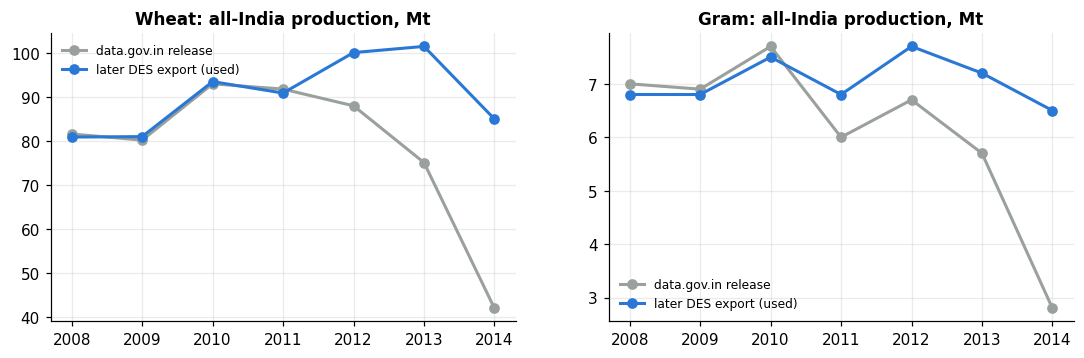

,crop,data_gov_in_release,later_DES_export
2008,Rice,95.3,96.1
2009,Rice,87.4,88.2
2010,Rice,95.2,95.3
2011,Rice,102.1,104.2
2012,Rice,100.3,107.4
2013,Rice,102.9,109.0
2014,Rice,104.0,109.7
2008,Wheat,81.6,80.9
2009,Wheat,80.2,81.0
2010,Wheat,93.0,93.5


In [5]:
rows = []
for crop in ["Rice", "Wheat", "Sugarcane", "Gram"]:
    o = old[old.Crop == crop].groupby("Crop_Year").Production.sum() / 1e6
    n = new[new.crop == crop].groupby("year").production.sum() / 1e6
    rows.append(pd.DataFrame({"crop": crop, "data_gov_in_release": o, "later_DES_export": n}).loc[2008:2014])
vint = pd.concat(rows).round(1)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, crop in zip(axes, ["Wheat", "Gram"]):
    d = vint[vint.crop == crop]
    ax.plot(d.index, d.data_gov_in_release, color=GREY, lw=2, marker="o", label="data.gov.in release")
    ax.plot(d.index, d.later_DES_export, color=BLUE, lw=2, marker="o", label="later DES export (used)")
    ax.set_title(f"{crop}: all-India production, Mt"); ax.legend(frameon=False, fontsize=8)
save(fig, "01_vintage_comparison")
vint

## 4. Coverage over time

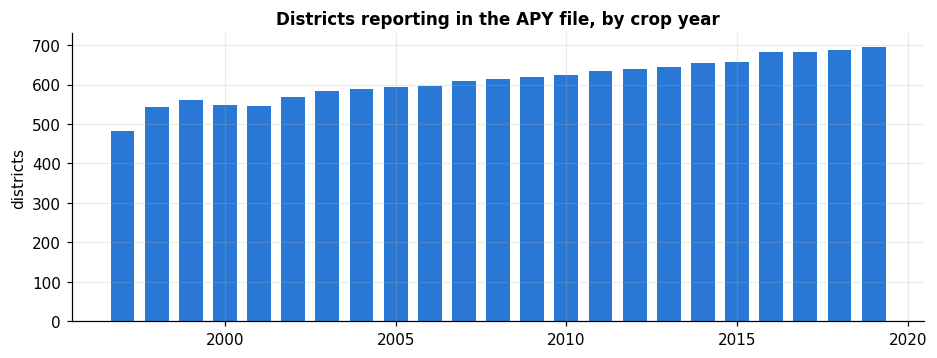

year,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019
rows,8378,11753,12647,13187,12951,13739,14132,13587,13330,13954,14005,14287,14482,14085,15118,14475,15173,14577,15365,16291,16489,16833,17703
districts,483,544,561,547,546,569,584,588,594,597,608,615,620,623,634,639,644,655,657,683,683,687,695
states,23,29,31,34,34,35,35,35,35,35,35,35,35,35,35,35,35,35,35,35,35,35,34


In [6]:
cov = new[new.year < 2020].groupby("year").agg(rows=("crop", "size"), districts=("district", "nunique"), states=("state", "nunique"))
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(cov.index, cov.districts, color=BLUE, width=.7)
ax.set_title("Districts reporting in the APY file, by crop year"); ax.set_ylabel("districts")
save(fig, "01_apy_coverage")
cov.T

**Takeaways**
- The two production files are **different vintages**: about 17% of overlapping state-year-crop totals differ (revisions and district re-mapping).
- The older data.gov.in release has obvious gaps in its final years (wheat 2014-15 = 42 Mt, gram 2.8 Mt), while the later export is complete. So the later export is used, and notebook 02 validates it against DES estimates.
- Coverage is fairly stable from 1998 onwards. 2020 contains only a handful of districts and is dropped in notebook 02.
- Mandi data comes in three windows: Maharashtra 2014-16 (monthly), one national day (30-Sep-2024), and ten national weeks of daily prices (Jul–Sep 2026, ~2,700 markets). There is no continuous 2017-2025 series.

## Conclusion
Every raw input is documented with publisher, coverage and access route.

## Limitations
Some sources come from mirrors because government portals need a sign-in; APY vintages differ.

## Next steps
Re-download directly from data.gov.in when an API key is available.